Ideal State Vector (|+⟩ State): 


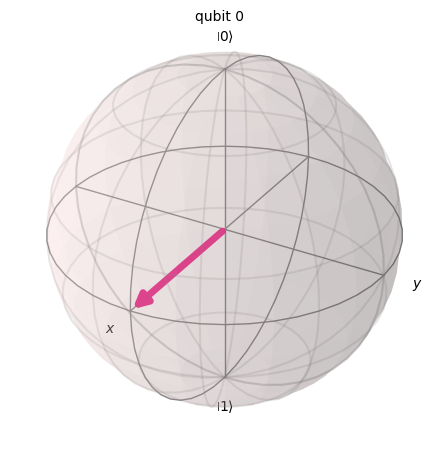

Noisy State Vector (Phase Flipped |-⟩ State):


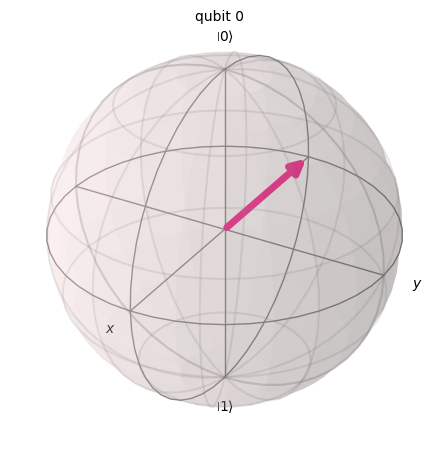

In [15]:
'''
To visualize phase flip
'''
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_bloch_multivector 

# 1. Ideal Qubit 0 state (after Hadamard)
qc_ideal = QuantumCircuit(1)
qc_ideal.h(0)
state_ideal = Statevector.from_instruction(qc_ideal)

# 2. Noisy Qubit 0 state (suffered a phase-flip error)
qc_noisy = QuantumCircuit(1)
qc_noisy.h(0)
qc_noisy.z(0) # Injected Phase Error
state_noisy = Statevector.from_instruction(qc_noisy)

# Visualize both on Bloch Spheres
print("Ideal State Vector (|+⟩ State): ")
display(plot_bloch_multivector(state_ideal))

print("Noisy State Vector (Phase Flipped |-⟩ State):")
display(plot_bloch_multivector(state_noisy))


BEFORE PHASE NOISE (|Φ+⟩):
AFTER PHASE NOISE (|Φ-⟩):


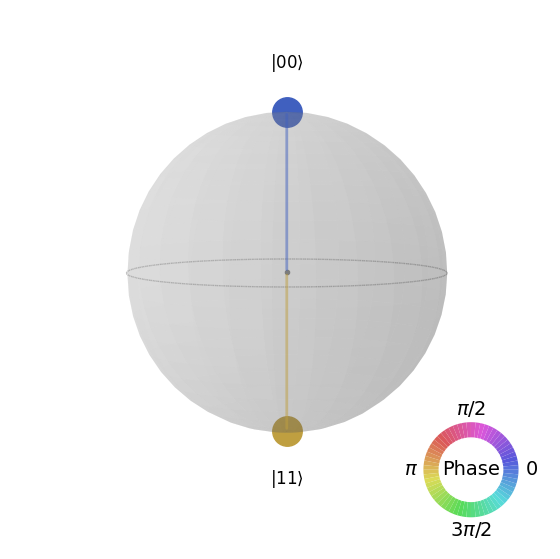

In [9]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# 1. BEFORE (Ideal Bell State: |Φ+⟩)
qc_before = QuantumCircuit(2)
qc_before.h(0)
qc_before.cx(0, 1)
state_before = Statevector.from_instruction(qc_before)

# 2. AFTER (Noisy Bell State with Phase Flip: |Φ-⟩)
qc_after = QuantumCircuit(2)
qc_after.h(0)
qc_after.z(0) # Injected phase-flip error on qubit 0
qc_after.cx(0, 1)
state_after = Statevector.from_instruction(qc_after)


print("BEFORE PHASE NOISE (|Φ+⟩):")
state_before.draw('qsphere')


print("AFTER PHASE NOISE (|Φ-⟩):")
state_after.draw('qsphere')


BEFORE (Ideal City Plot):
BEFORE (Ideal City Plot):


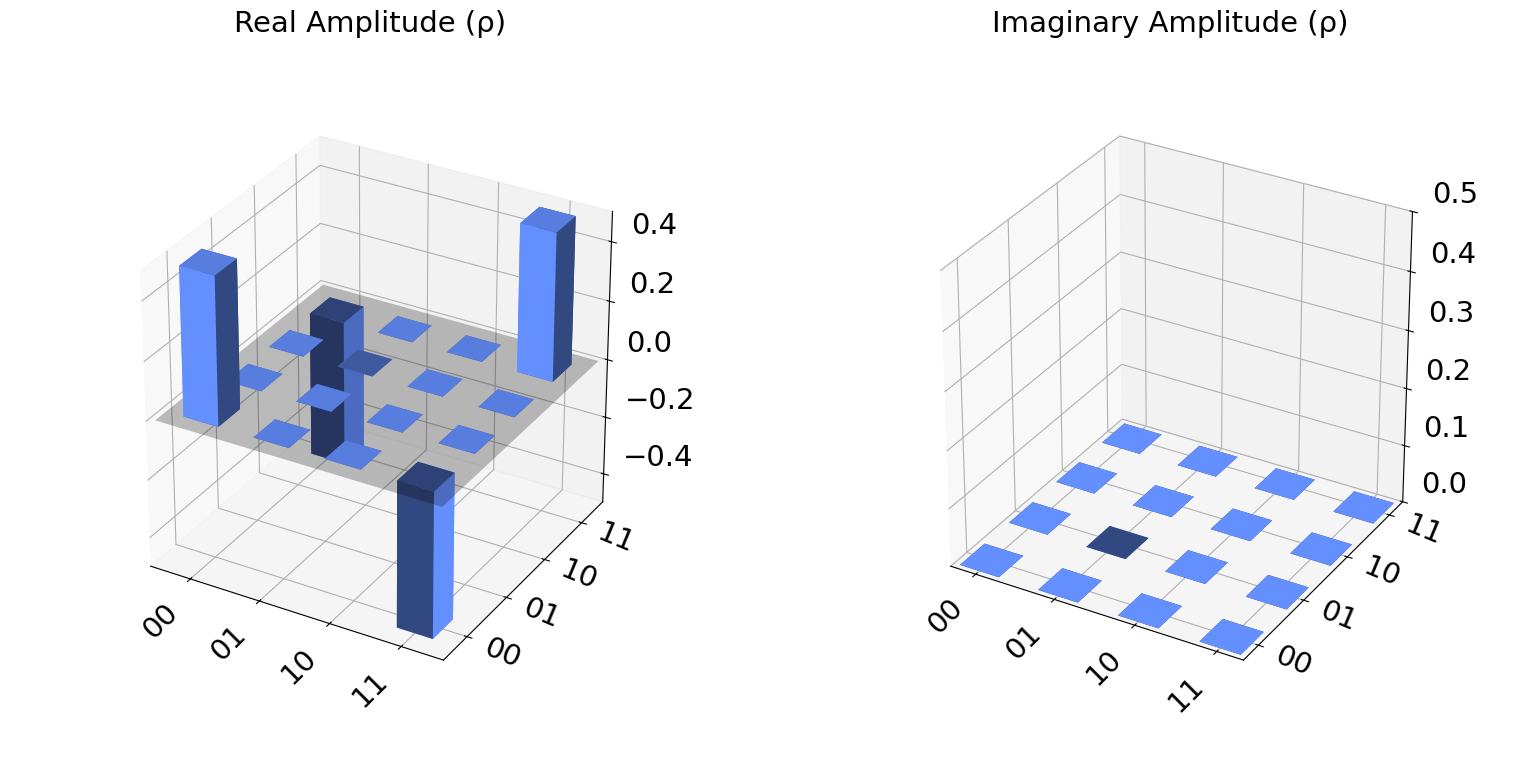

In [10]:
print("BEFORE (Ideal City Plot):")
state_before.draw('city')

print("BEFORE (Ideal City Plot):")
state_after.draw('city')

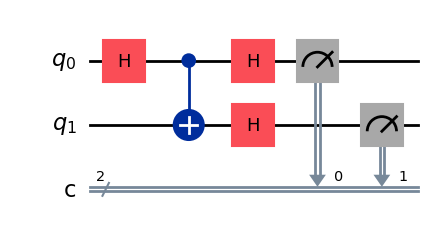

In [12]:
from qiskit import QuantumCircuit, transpile
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, pauli_error

# Build standard Bell Circuit
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)

# Change Basis to X-basis before measuring 
qc.h(0)
qc.h(1)
qc.measure([0, 1], [0, 1])

# Setup a 100% intentional phase-flip error on the H gate to test it
phase_error = pauli_error([('Z', 1.0), ('I', 0.0)])
noise_model = NoiseModel()
noise_model.add_all_qubit_quantum_error(phase_error, ["h"])   # Apply to H gate


qc.draw(output="mpl")

X-Basis Measurement Counts: {'10': 528, '01': 496}


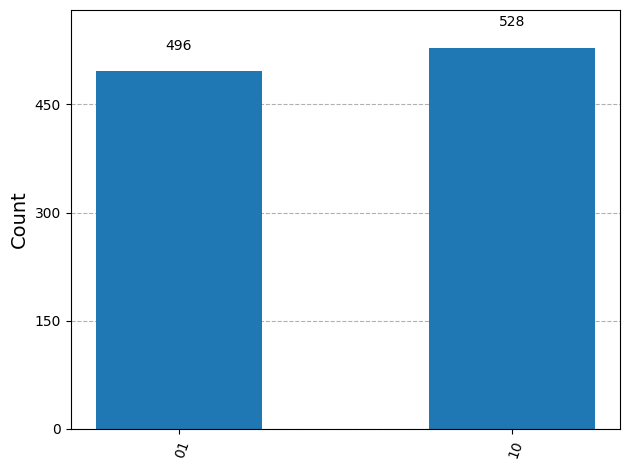

In [13]:
# Simulate
backend = AerSimulator(noise_model=noise_model)
pm = generate_preset_pass_manager(backend=backend, optimization_level=1) # Transpile the circuit to the simulator's basis gates
isa_circuit = pm.run(qc)

# Run the noisy simulation
job = backend.run(isa_circuit, shots=1024)
noisy_counts = job.result().get_counts()

print("X-Basis Measurement Counts:", noisy_counts)
plot_histogram(noisy_counts)

Ideal X-Basis Measurement Counts: {'00': 536, '11': 488}


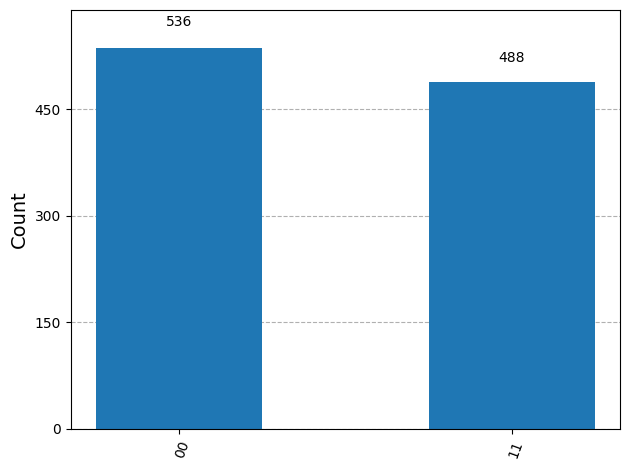

In [14]:
'''
Ideal Bell without errors measuing on X-basis
'''
from qiskit import QuantumCircuit
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Create a 2-qubit circuit, build the Ideal Bell State (|Φ+⟩)
qc_ideal = QuantumCircuit(2)
qc_ideal.h(0)
qc_ideal.cx(0, 1)

# Change basis to the X-basis right before measuring
# (Applying an H gate maps the X-basis eigenstates to the computational Z-basis)
qc_ideal.h(0)
qc_ideal.h(1)

qc_ideal.measure_all()

# Simulate using an ideal (noiseless) simulator backend
backend = AerSimulator()
pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
isa_circuit = pm.run(qc_ideal)

# Execute the simulation
job = backend.run(isa_circuit, shots=1024)
ideal_x_counts = job.result().get_counts()

print("Ideal X-Basis Measurement Counts:", ideal_x_counts)
plot_histogram(ideal_x_counts)
